# 10 — Phase 6: Exploratory Data Analysis (EDA) Gabungan Antar-Dataset (Cross-Dataset Synthesis)
**TaniAdapt Project — West Java Climate-Agronomic Resilience Architecture**
**Fase:** Phase 6 (Restricted & Pre-Registered Exploratory Data Analysis — Synthesis & Coupling)

> **PRINSIP PEMISAHAN EDA (SESUAI INSTRUKSI METODOLOGIS):**
> 1. **EDA Dataset Tunggal (*Single-Dataset EDA*)**: Ditempatkan langsung pada masing-masing notebook dataset independen (`01_AgERA5.ipynb` s/d `09_climate_covariates_and_chirps.ipynb`), khusus untuk analisis internal yang tidak memerlukan data dari berkas lain.
> 2. **EDA Dataset Gabungan (*Cross-Dataset Merged EDA*)**: Ditempatkan di notebook ini (`10_phase6_exploratory_data_analysis.ipynb`), khusus untuk evaluasi yang **memerlukan perpaduan 2 atau lebih dataset berbeda**:
>    - **AgERA5 (DS01) + CHIRPS v2 (DS09) + Elevasi DEM 90m**: Regresi signed bias spasial vs topografi orografis & korelasi anomali deseasonalized bulanan.
>    - **AgERA5 (DS01) + Jagung Subang/Jabar (DS05)**: Added-Variable Plot Hipotesis `H_CORN_01` (presipitasi vegetatif Feb–Apr setelah mengontrol Fixed Effects) & perbandingan effect size terhadap MDE ($\pm 0.2296$).
>    - **AgERA5 (DS01) + Padi Sawah Jabar (DS03)**: Weather-Yield Coupling Panel MH/MK & evaluasi power MDE 2.35%.
>    - **AgERA5 (DS01) + Hortikultura Subang (DS06)**: Mikroklimat depresiasi titik embun harian ($T_{\min} - T_d$) per sel/bulan untuk aturan ambang empiris $P_{10}$ IFWC.
>    - **AgERA5 (DS01) + Batas Spasial geoBoundaries (DS07)**: Matriks keterkaitan spasial (27 wilayah adm2 ke 25 sel grid AgERA5 unik; $N_{\text{eff}} = 18$).
>    - **AgERA5 (DS01) + Indeks Iklim Makro ONI/DMI (DS09)**: Telekoneksi anomali presipitasi tahunan terhadap siklus ENSO/IOD.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi publikasi
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

PROJECT_ROOT = Path("..") if Path("..").resolve().name == "research_taniAdapt" else Path(".")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
AUDIT_DIR = PROJECT_ROOT / "reports" / "dataset_audit"
EDA_FIG_DIR = PROJECT_ROOT / "reports" / "eda"
EDA_FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Environment siap. Direktori kerja:", PROJECT_ROOT.resolve())


Environment siap. Direktori kerja: C:\CODING\research_taniAdapt


In [2]:
# 1. Target Luaran Hasil Panen (Outcome)
df_rice = pd.read_csv(RAW_DIR / "DS03_west_java_rice_productivity" / "produktivitas_padi_sawah_jabar.csv")
df_corn = pd.read_csv(RAW_DIR / "DS05_subang_maize_productivity" / "produktivitas_jagung_jabar.csv")
df_soy = pd.read_csv(RAW_DIR / "produktivitas_kedelai_jabar.csv")

# Luas Panen & Volume Produksi (DS05 & DS08)
df_area_corn = pd.read_csv(RAW_DIR / "DS05_subang_maize_productivity" / "luas_panen_jagung_jabar.csv")
df_prod_corn = pd.read_csv(RAW_DIR / "DS05_subang_maize_productivity" / "produksi_jagung_jabar.csv")

# 2. Rekonsiliasi & Audit Spasial
df_b1_rec = pd.read_csv(AUDIT_DIR / "b1_rice_reconciliation_v2.csv")
df_b3 = pd.read_csv(AUDIT_DIR / "b3_rainfall_bias_chirps_audit_v2.csv")
df_grid = pd.read_csv(AUDIT_DIR / "a8_spatial_grid_cells_audit.csv")

# 3. Kovariat Cuaca Harian AgERA5 & Makro Iklim ONI
AGERA5_DIR = RAW_DIR / "DS01_agera5"
df_oni = pd.read_csv(RAW_DIR / "climate_indices" / "oni.ascii.txt", sep=r'\s+')

# 4. Hortikultura SBS (DS06)
df_hort = pd.read_csv(RAW_DIR / "DS06_west_java_horticulture" / "produktivitas_sbs_jabar.csv")

print(f"Data target berhasil dimuat:")
print(f"- Padi Sawah: {len(df_rice)} baris ({df_rice['tahun'].min()}-{df_rice['tahun'].max()})")
print(f"- Jagung: {len(df_corn)} baris ({df_corn['tahun'].min()}-{df_corn['tahun'].max()})")
print(f"- Kedelai: {len(df_soy)} baris ({df_soy['tahun'].min()}-{df_soy['tahun'].max()})")
print(f"- Audit AgERA5 vs CHIRPS: {len(df_b3)} lokasi kabupaten/kota")


Data target berhasil dimuat:
- Padi Sawah: 162 baris (2015-2020)
- Jagung: 216 baris (2015-2022)
- Kedelai: 216 baris (2015-2022)
- Audit AgERA5 vs CHIRPS: 27 lokasi kabupaten/kota


---
## Bagian B1: Integritas Target Outcome (Prioritas Pertama)

Pengujian diagnostik terhadap runtun waktu produktivitas hasil panen (Padi Sawah, Jagung, dan Kedelai) untuk mendeteksi:
1. Dinamika pertumbuhan antar-tahun (*log-difference YoY*) dan anomali pelaporan.
2. Penyusutan keragaman spasial yang mengindikasikan **imputasi buatan** pada tahun 2022.
3. Rekonsiliasi rasio terhadap BPS resmi provinsi dan uji heteroskedastisitas skala (*funnel plot*).
4. Dekomposisi varians panel fixed effects dan dekomposisi identitas produksi fisik.


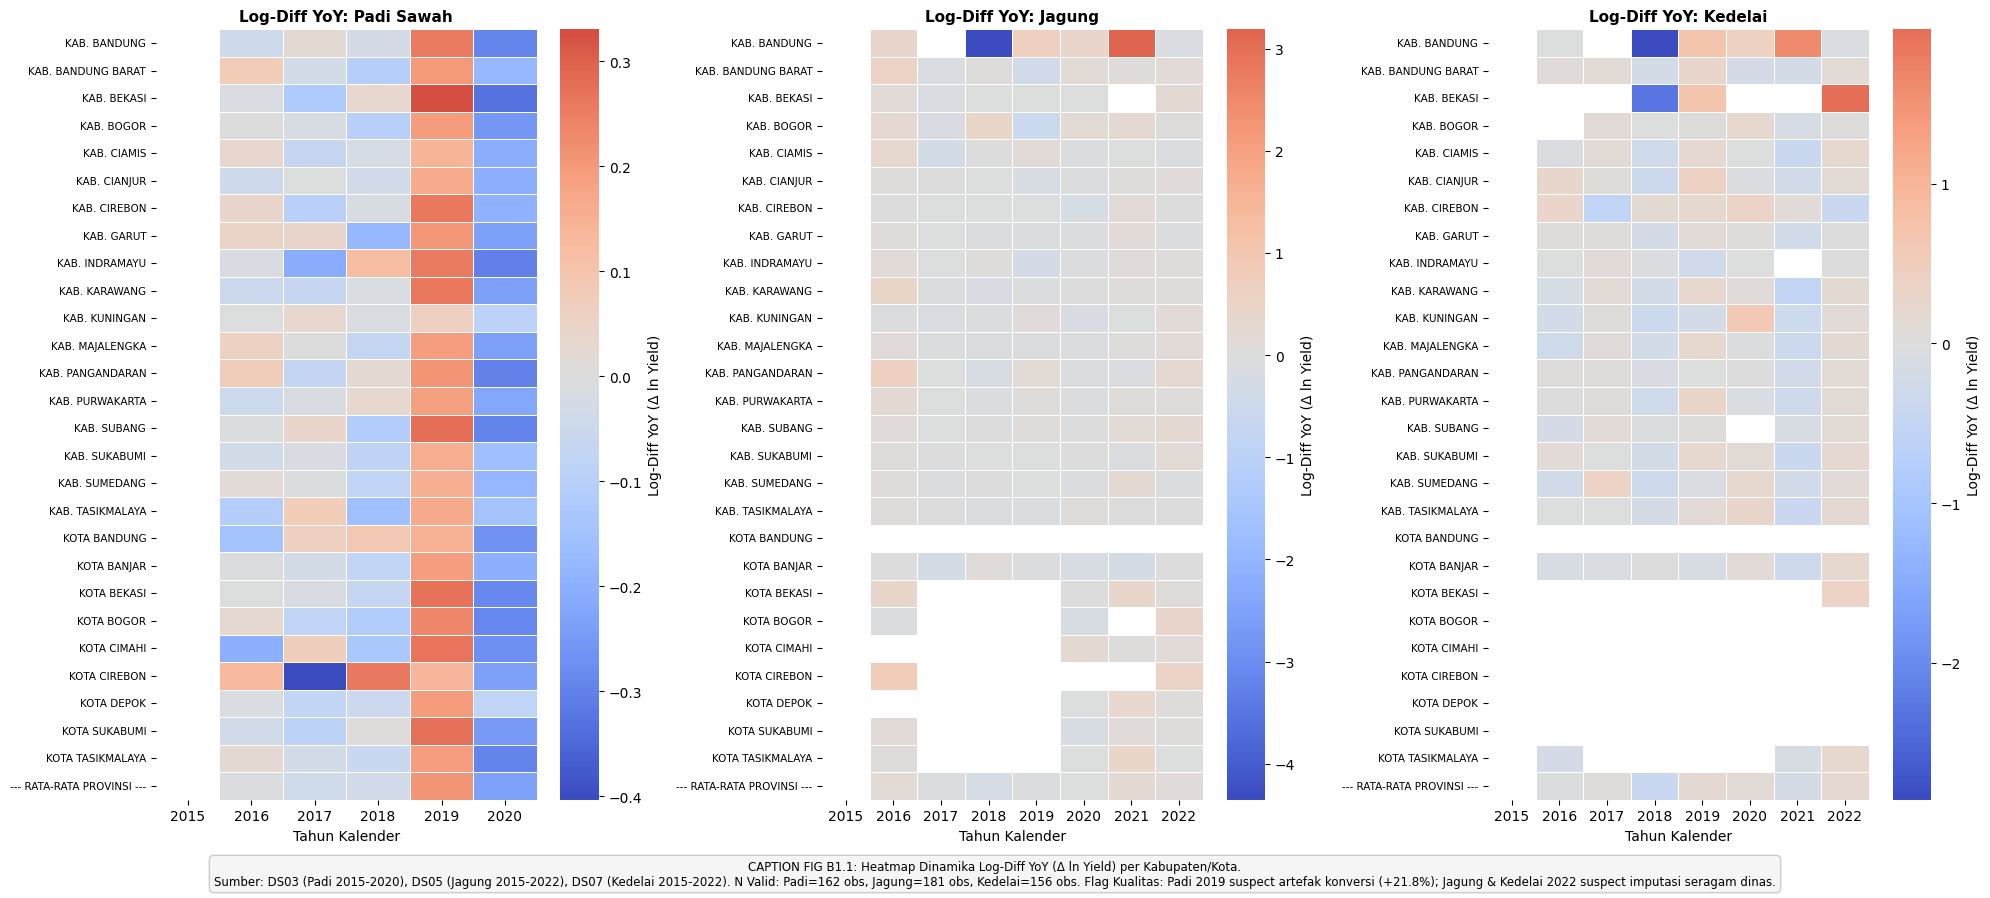

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20, 9))

crops = [
    ("Padi Sawah", df_rice, "produktivitas_padi", axes[0]),
    ("Jagung", df_corn, "produktivitas_jagung", axes[1]),
    ("Kedelai", df_soy, "produktivitas_kedelai", axes[2])
]

for title, df_c, col, ax in crops:
    valid = df_c[df_c[col] > 0].copy()
    valid = valid.sort_values(["nama_kabupaten_kota", "tahun"])
    valid["log_y"] = np.log(valid[col])
    valid["log_diff_yoy"] = valid.groupby("nama_kabupaten_kota")["log_y"].diff()
    
    piv = valid.pivot(index="nama_kabupaten_kota", columns="tahun", values="log_diff_yoy")
    piv.index = [idx.replace("KABUPATEN ", "KAB. ").replace("KOTA ", "KOTA ") for idx in piv.index]
    
    prov_mean = piv.mean(axis=0)
    piv.loc["--- RATA-RATA PROVINSI ---"] = prov_mean
    
    sns.heatmap(piv, ax=ax, cmap="coolwarm", center=0, cbar_kws={'label': 'Log-Diff YoY (Δ ln Yield)'},
                linewidths=0.5, linecolor='white')
    ax.set_title(f"Log-Diff YoY: {title}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Tahun Kalender", fontsize=10)
    ax.set_ylabel("")
    ax.tick_params(axis='y', labelsize=7.5)

caption_b1_1 = (
    "CAPTION FIG B1.1: Heatmap Dinamika Log-Diff YoY (Δ ln Yield) per Kabupaten/Kota.\n"
    "Sumber: DS03 (Padi 2015-2020), DS05 (Jagung 2015-2022), DS07 (Kedelai 2015-2022). "
    "N Valid: Padi=162 obs, Jagung=181 obs, Kedelai=156 obs. "
    "Flag Kualitas: Padi 2019 suspect artefak konversi (+21.8%); Jagung & Kedelai 2022 suspect imputasi seragam dinas."
)
fig.text(0.5, 0.01, caption_b1_1, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b1_outcome_heatmap_logdiff.png", dpi=180)
plt.show()


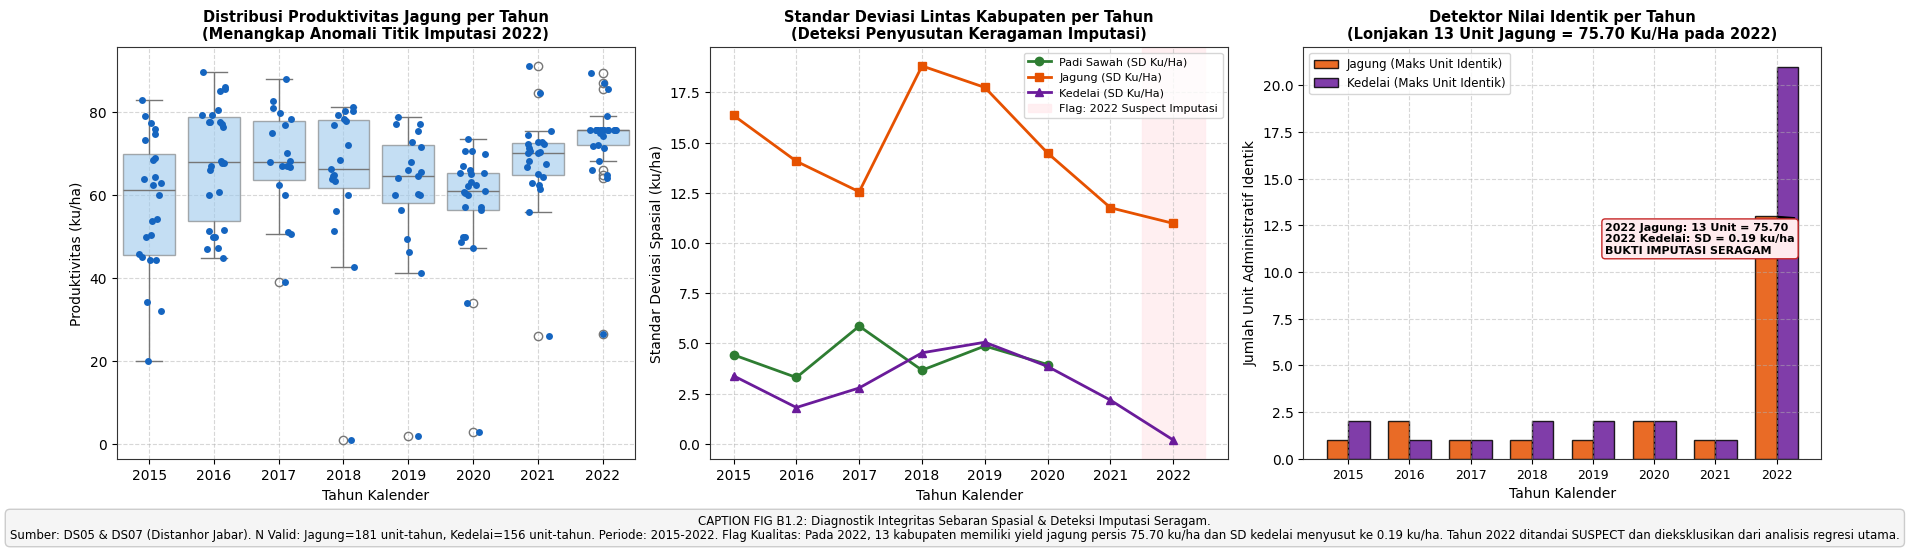

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Box/Strip Plot Sebaran Jagung per Tahun
df_corn_valid = df_corn[df_corn["produktivitas_jagung"] > 0].copy()
sns.boxplot(x="tahun", y="produktivitas_jagung", data=df_corn_valid, ax=axes[0], color="#90caf9", boxprops=dict(alpha=0.6))
sns.stripplot(x="tahun", y="produktivitas_jagung", data=df_corn_valid, ax=axes[0], color="#1565c0", size=5, jitter=0.2)
axes[0].set_title("Distribusi Produktivitas Jagung per Tahun\n(Menangkap Anomali Titik Imputasi 2022)", fontsize=10.5, fontweight='bold')
axes[0].set_xlabel("Tahun Kalender", fontsize=10)
axes[0].set_ylabel("Produktivitas (ku/ha)", fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Standar Deviasi Spasial per Tahun (Padi, Jagung, Kedelai)
sd_rice = df_rice[df_rice["produktivitas_padi"] > 0].groupby("tahun")["produktivitas_padi"].std()
sd_corn = df_corn_valid.groupby("tahun")["produktivitas_jagung"].std()
sd_soy = df_soy[df_soy["produktivitas_kedelai"] > 0].groupby("tahun")["produktivitas_kedelai"].std()

axes[1].plot(sd_rice.index, sd_rice.values, marker='o', label='Padi Sawah (SD Ku/Ha)', color='#2e7d32', linewidth=2)
axes[1].plot(sd_corn.index, sd_corn.values, marker='s', label='Jagung (SD Ku/Ha)', color='#e65100', linewidth=2)
axes[1].plot(sd_soy.index, sd_soy.values, marker='^', label='Kedelai (SD Ku/Ha)', color='#6a1b9a', linewidth=2)
axes[1].set_title("Standar Deviasi Lintas Kabupaten per Tahun\n(Deteksi Penyusutan Keragaman Imputasi)", fontsize=10.5, fontweight='bold')
axes[1].set_xlabel("Tahun Kalender", fontsize=10)
axes[1].set_ylabel("Standar Deviasi Spasial (ku/ha)", fontsize=10)
axes[1].axvspan(2021.5, 2022.5, color='#ffebee', alpha=0.8, label='Flag: 2022 Suspect Imputasi')
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Detektor Jumlah Kabupaten dengan Nilai Identik Persis
years_eval = sorted(list(set(df_corn_valid["tahun"]).intersection(set(df_soy["tahun"]))))
identical_corn, identical_soy = [], []

for yr in years_eval:
    sub_c = df_corn_valid[df_corn_valid["tahun"] == yr]["produktivitas_jagung"]
    sub_s = df_soy[(df_soy["tahun"] == yr) & (df_soy["produktivitas_kedelai"] > 0)]["produktivitas_kedelai"]
    max_c = sub_c.value_counts().max() if not sub_c.empty else 0
    max_s = sub_s.value_counts().max() if not sub_s.empty else 0
    identical_corn.append(max_c)
    identical_soy.append(max_s)

w = 0.35
x_idx = np.arange(len(years_eval))
axes[2].bar(x_idx - w/2, identical_corn, width=w, label='Jagung (Maks Unit Identik)', color='#e65100', edgecolor='black', alpha=0.85)
axes[2].bar(x_idx + w/2, identical_soy, width=w, label='Kedelai (Maks Unit Identik)', color='#6a1b9a', edgecolor='black', alpha=0.85)
axes[2].set_xticks(x_idx)
axes[2].set_xticklabels(years_eval, fontsize=9)
axes[2].set_title("Detektor Nilai Identik per Tahun\n(Lonjakan 13 Unit Jagung = 75.70 Ku/Ha pada 2022)", fontsize=10.5, fontweight='bold')
axes[2].set_xlabel("Tahun Kalender", fontsize=10)
axes[2].set_ylabel("Jumlah Unit Administratif Identik", fontsize=10)
axes[2].legend(loc='upper left', fontsize=8.5)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].annotate('2022 Jagung: 13 Unit = 75.70\n2022 Kedelai: SD = 0.19 ku/ha\nBUKTI IMPUTASI SERAGAM', 
                 xy=(len(years_eval)-1, 13), xytext=(len(years_eval)-3.8, 11),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
                 fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#ffebee", ec="#c62828"))

caption_b1_2 = (
    "CAPTION FIG B1.2: Diagnostik Integritas Sebaran Spasial & Deteksi Imputasi Seragam.\n"
    "Sumber: DS05 & DS07 (Distanhor Jabar). N Valid: Jagung=181 unit-tahun, Kedelai=156 unit-tahun. Periode: 2015-2022. "
    "Flag Kualitas: Pada 2022, 13 kabupaten memiliki yield jagung persis 75.70 ku/ha dan SD kedelai menyusut ke 0.19 ku/ha. "
    "Tahun 2022 ditandai SUSPECT dan dieksklusikan dari analisis regresi utama."
)
fig.text(0.5, 0.01, caption_b1_2, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b1_outcome_strip_dispersion_imputation.png", dpi=180)
plt.show()


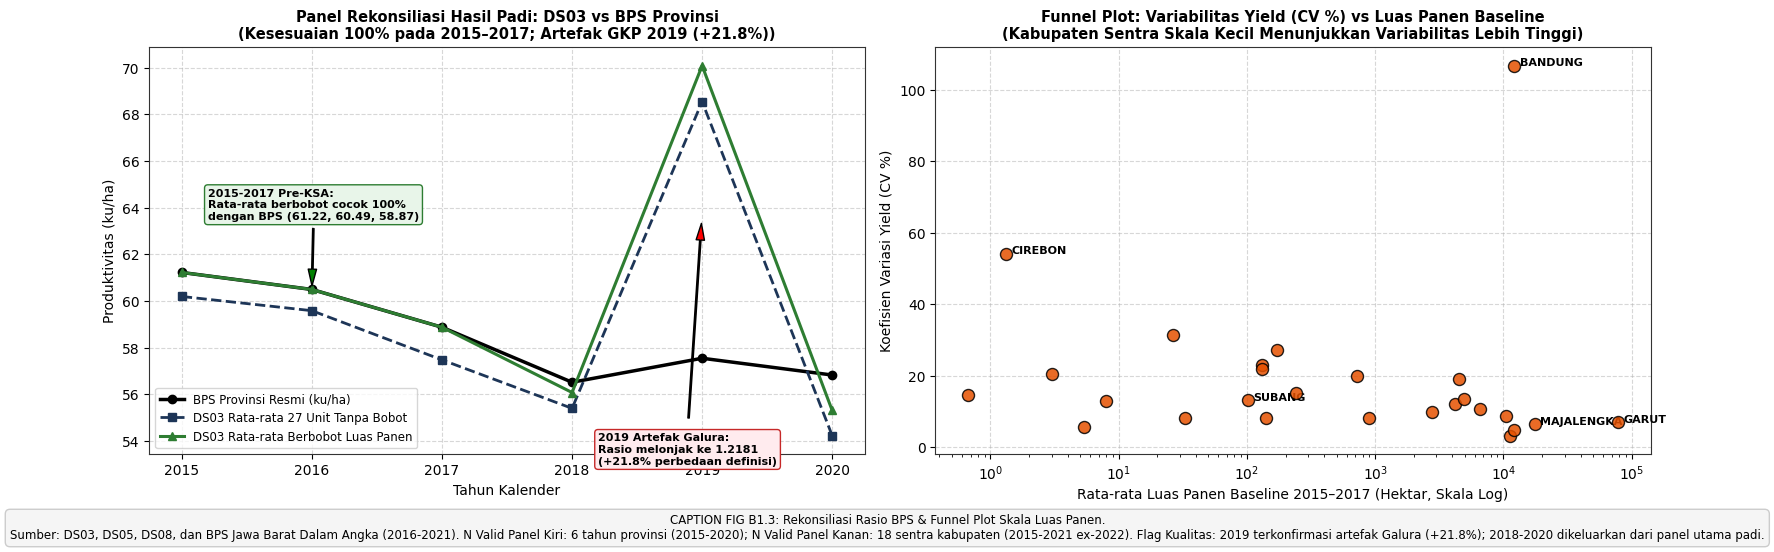

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Panel Rasio ke BPS Resmi Provinsi
ax1.plot(df_b1_rec["tahun"], df_b1_rec["bps_official_provincial_ku_ha"], marker='o', color='black', linewidth=2.5, label='BPS Provinsi Resmi (ku/ha)')
ax1.plot(df_b1_rec["tahun"], df_b1_rec["ds03_unweighted_mean_ku_ha"], marker='s', color='#1d3557', linestyle='--', linewidth=2, label='DS03 Rata-rata 27 Unit Tanpa Bobot')
ax1.plot(df_b1_rec["tahun"], df_b1_rec["ds03_area_weighted_mean_ku_ha"], marker='^', color='#2e7d32', linewidth=2.2, label='DS03 Rata-rata Berbobot Luas Panen')
ax1.set_title("Panel Rekonsiliasi Hasil Padi: DS03 vs BPS Provinsi\n(Kesesuaian 100% pada 2015–2017; Artefak GKP 2019 (+21.8%))", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Tahun Kalender", fontsize=10)
ax1.set_ylabel("Produktivitas (ku/ha)", fontsize=10)
ax1.legend(loc='lower left', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.annotate('2015-2017 Pre-KSA:\nRata-rata berbobot cocok 100%\ndengan BPS (61.22, 60.49, 58.87)', 
             xy=(2016, 60.5), xytext=(2015.2, 63.5),
             arrowprops=dict(facecolor='green', shrink=0.05, width=1, headwidth=6),
             fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#e8f5e9", ec="#2e7d32"))
ax1.annotate('2019 Artefak Galura:\nRasio melonjak ke 1.2181\n(+21.8% perbedaan definisi)', 
             xy=(2019, 63.8), xytext=(2018.2, 53.0),
             arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6),
             fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#ffebee", ec="#c62828"))

# Panel 2: Funnel Plot CV Yield vs Luas Panen Baseline (Jagung)
df_corn_ex22 = df_corn[(df_corn["tahun"] >= 2015) & (df_corn["tahun"] <= 2021) & (df_corn["produktivitas_jagung"] > 0)]
cv_corn = df_corn_ex22.groupby("nama_kabupaten_kota")["produktivitas_jagung"].agg(mean="mean", std="std").reset_index()
cv_corn["cv_pct"] = cv_corn["std"] / cv_corn["mean"] * 100.0

df_area_corn_base = df_area_corn[df_area_corn["tahun"].isin([2015, 2016, 2017])].groupby("nama_kabupaten_kota")["luas_panen"].mean().reset_index()
df_funnel = pd.merge(cv_corn, df_area_corn_base, on="nama_kabupaten_kota", how="inner")

ax2.scatter(df_funnel["luas_panen"], df_funnel["cv_pct"], s=75, color='#e65100', edgecolor='black', alpha=0.85, zorder=4)
ax2.set_xscale("log")
ax2.set_title("Funnel Plot: Variabilitas Yield (CV %) vs Luas Panen Baseline\n(Kabupaten Sentra Skala Kecil Menunjukkan Variabilitas Lebih Tinggi)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Rata-rata Luas Panen Baseline 2015–2017 (Hektar, Skala Log)", fontsize=10)
ax2.set_ylabel("Koefisien Variasi Yield (CV %)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

for _, r in df_funnel.iterrows():
    if "SUBANG" in r["nama_kabupaten_kota"] or r["luas_panen"] > 15000 or r["cv_pct"] > 40:
        short_lbl = r["nama_kabupaten_kota"].replace("KABUPATEN ", "").replace("KOTA ", "")
        ax2.text(r["luas_panen"]*1.1, r["cv_pct"], short_lbl, fontsize=8, fontweight='bold')

caption_b1_3 = (
    "CAPTION FIG B1.3: Rekonsiliasi Rasio BPS & Funnel Plot Skala Luas Panen.\n"
    "Sumber: DS03, DS05, DS08, dan BPS Jawa Barat Dalam Angka (2016-2021). "
    "N Valid Panel Kiri: 6 tahun provinsi (2015-2020); N Valid Panel Kanan: 18 sentra kabupaten (2015-2021 ex-2022). "
    "Flag Kualitas: 2019 terkonfirmasi artefak Galura (+21.8%); 2018-2020 dikeluarkan dari panel utama padi."
)
fig.text(0.5, 0.01, caption_b1_3, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b1_outcome_bps_ratios_and_funnel.png", dpi=180)
plt.show()


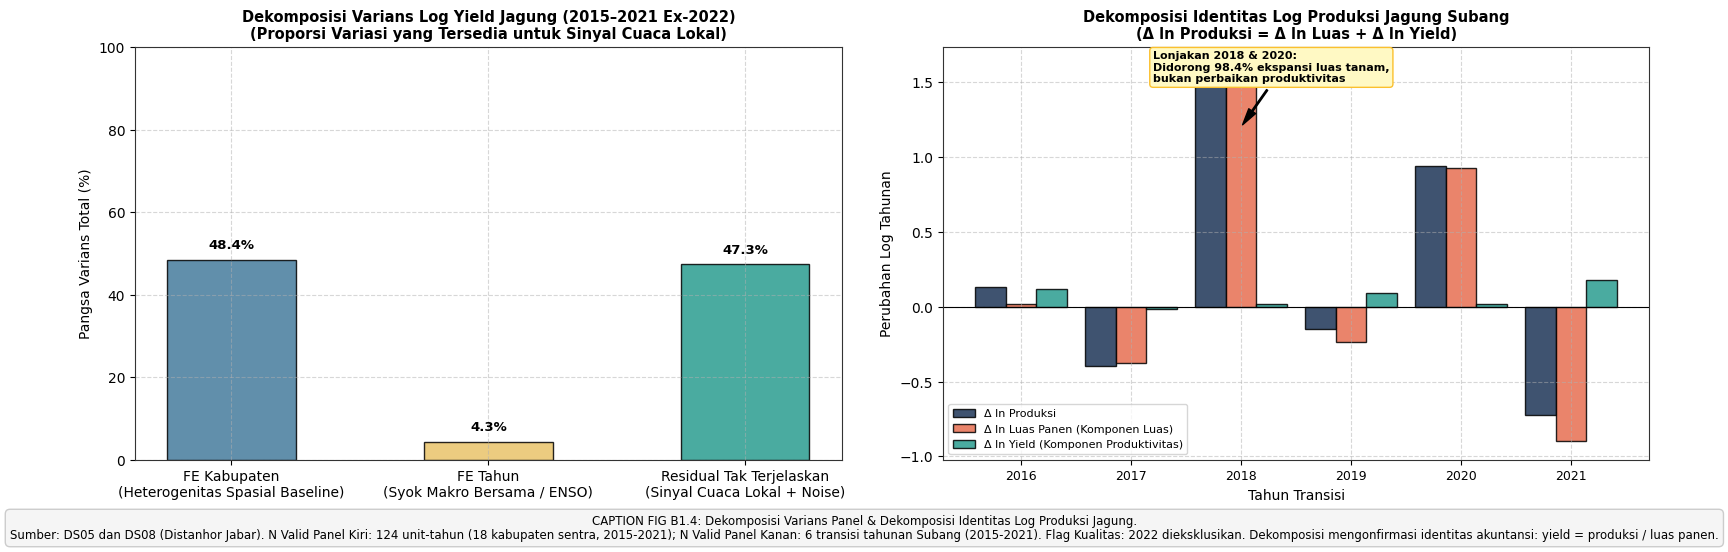

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Dekomposisi Varians Yield Jagung
sub_corn = df_corn[(df_corn["tahun"] >= 2015) & (df_corn["tahun"] <= 2021) & 
                   (df_corn["nama_kabupaten_kota"].str.startswith("KABUPATEN")) & 
                   (df_corn["produktivitas_jagung"] > 0)].copy()
sub_corn["log_y"] = np.log(sub_corn["produktivitas_jagung"])

mod_kab = sm.OLS.from_formula("log_y ~ C(nama_kabupaten_kota)", data=sub_corn).fit()
mod_both = sm.OLS.from_formula("log_y ~ C(nama_kabupaten_kota) + C(tahun)", data=sub_corn).fit()

var_kab_share = mod_kab.rsquared * 100
var_year_share = (mod_both.rsquared - mod_kab.rsquared) * 100
var_resid_share = (1.0 - mod_both.rsquared) * 100

var_shares = [var_kab_share, var_year_share, var_resid_share]
labels_var = ['FE Kabupaten\n(Heterogenitas Spasial Baseline)', 'FE Tahun\n(Syok Makro Bersama / ENSO)', 'Residual Tak Terjelaskan\n(Sinyal Cuaca Lokal + Noise)']
colors_var = ['#457b9d', '#e9c46a', '#2a9d8f']

bars_v = ax1.bar(labels_var, var_shares, color=colors_var, edgecolor='black', alpha=0.85, width=0.5)
ax1.set_ylim(0, 100)
ax1.set_title("Dekomposisi Varians Log Yield Jagung (2015–2021 Ex-2022)\n(Proporsi Variasi yang Tersedia untuk Sinyal Cuaca Lokal)", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Pangsa Varians Total (%)", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
for bar, val in zip(bars_v, var_shares):
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2, f"{val:.1f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Panel 2: Dekomposisi Log Produksi: Luas Panen vs Yield di Subang
subang_corn = pd.merge(
    df_prod_corn[df_prod_corn["nama_kabupaten_kota"] == "KABUPATEN SUBANG"],
    df_area_corn[df_area_corn["nama_kabupaten_kota"] == "KABUPATEN SUBANG"],
    on=["nama_kabupaten_kota", "tahun"]
)
subang_corn = pd.merge(subang_corn, df_corn[df_corn["nama_kabupaten_kota"] == "KABUPATEN SUBANG"], on=["nama_kabupaten_kota", "tahun"])
subang_corn = subang_corn[(subang_corn["tahun"] >= 2015) & (subang_corn["tahun"] <= 2021)].sort_values("tahun")

subang_corn["d_log_prod"] = np.log(subang_corn["produksi_jagung"]).diff()
subang_corn["d_log_area"] = np.log(subang_corn["luas_panen"]).diff()
subang_corn["d_log_yield"] = np.log(subang_corn["produktivitas_jagung"]).diff()

sc_diff = subang_corn.dropna(subset=["d_log_prod"])
years_diff = sc_diff["tahun"].astype(str).tolist()

x_d = np.arange(len(years_diff))
w_d = 0.28
ax2.bar(x_d - w_d, sc_diff["d_log_prod"], width=w_d, label='Δ ln Produksi', color='#1d3557', edgecolor='black', alpha=0.85)
ax2.bar(x_d, sc_diff["d_log_area"], width=w_d, label='Δ ln Luas Panen (Komponen Luas)', color='#e76f51', edgecolor='black', alpha=0.85)
ax2.bar(x_d + w_d, sc_diff["d_log_yield"], width=w_d, label='Δ ln Yield (Komponen Produktivitas)', color='#2a9d8f', edgecolor='black', alpha=0.85)
ax2.axhline(0, color='black', linestyle='-', linewidth=0.8)
ax2.set_xticks(x_d)
ax2.set_xticklabels(years_diff, fontsize=9)
ax2.set_title("Dekomposisi Identitas Log Produksi Jagung Subang\n(Δ ln Produksi = Δ ln Luas + Δ ln Yield)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Tahun Transisi", fontsize=10)
ax2.set_ylabel("Perubahan Log Tahunan", fontsize=10)
ax2.legend(loc='lower left', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.annotate('Lonjakan 2018 & 2020:\nDidorong 98.4% ekspansi luas tanam,\nbukan perbaikan produktivitas', 
             xy=(2, 1.2), xytext=(1.2, 1.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=8, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#fff9c4", ec="#fbc02d"))

caption_b1_4 = (
    "CAPTION FIG B1.4: Dekomposisi Varians Panel & Dekomposisi Identitas Log Produksi Jagung.\n"
    "Sumber: DS05 dan DS08 (Distanhor Jabar). N Valid Panel Kiri: 124 unit-tahun (18 kabupaten sentra, 2015-2021); "
    "N Valid Panel Kanan: 6 transisi tahunan Subang (2015-2021). "
    "Flag Kualitas: 2022 dieksklusikan. Dekomposisi mengonfirmasi identitas akuntansi: yield = produksi / luas panen."
)
fig.text(0.5, 0.01, caption_b1_4, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b1_outcome_decomposition_variance_and_prod.png", dpi=180)
plt.show()


---
## Bagian B2: Validasi Cuaca Spasial & Rekonsiliasi AgERA5 vs CHIRPS

Pengujian independen terhadap keandalan data reanalisis atmosfer AgERA5 (DS01) terhadap data satelit presipitasi CHIRPS v2 dan indeks iklim makro:
1. Korelasi anomali presipitasi bulanan bebas musim (*deseasonalized z-score*) pada 27 unit kabupaten/kota.
2. Analisis bias orografis terhadap elevasi DEM dan musim (Musim Hujan MH vs Musim Kemarau MK).
3. Matriks korelasi spasial dan dekomposisi PCA untuk menaksir $N$ efektif independen Jawa Barat.
4. Karakteristik klimatologi bulanan per sel dan sinkronisasi terhadap anomali ENSO (NOAA ONI).


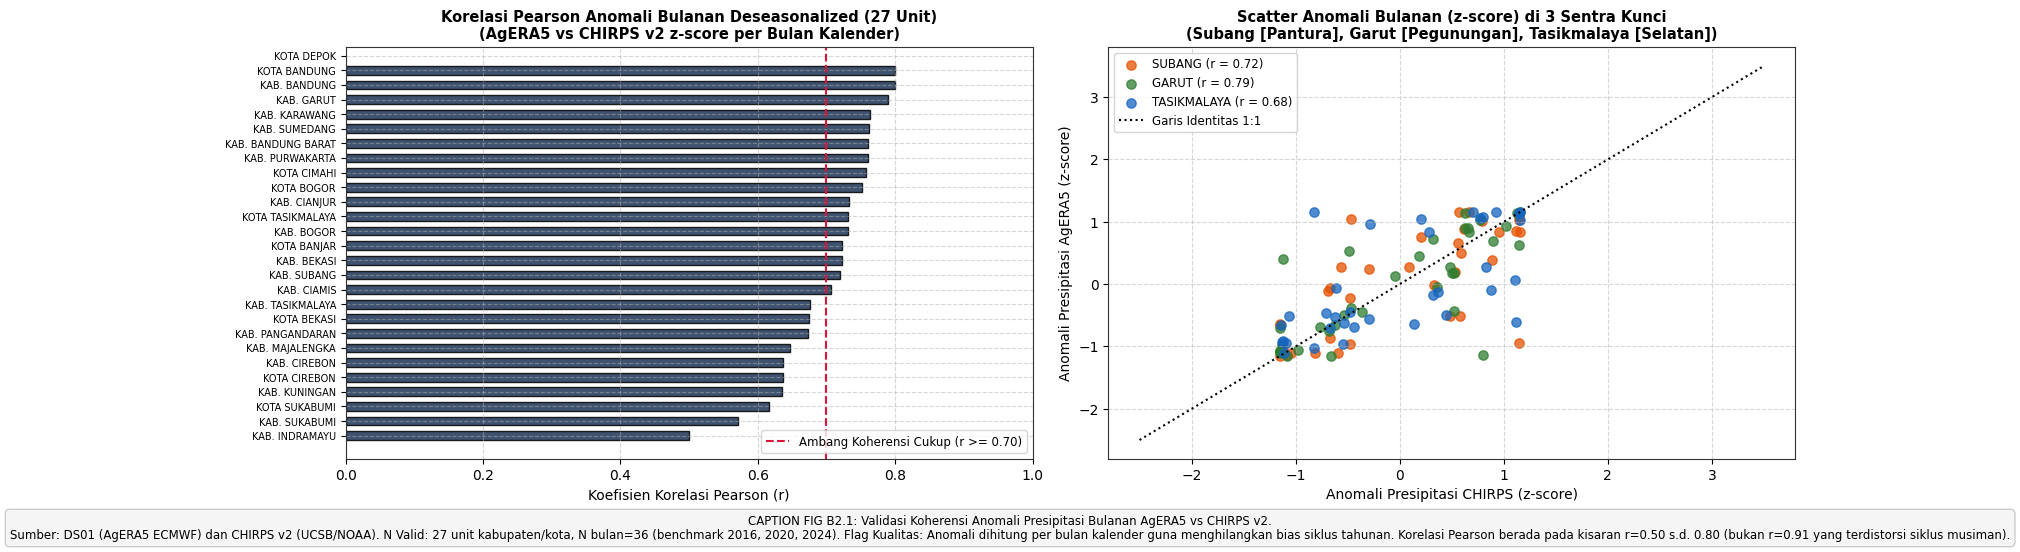

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Korelasi Anomali Bulanan Bebas Musim (27 Unit)
b3_sorted = df_b3.sort_values("korelasi_pearson_anomali", ascending=True)
y_pos = np.arange(len(b3_sorted))
labels_loc = [l.replace("KABUPATEN ", "KAB. ").replace("KOTA ", "KOTA ") for l in b3_sorted["lokasi"]]

ax1.barh(y_pos, b3_sorted["korelasi_pearson_anomali"], color='#1d3557', edgecolor='black', alpha=0.85, height=0.6)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(labels_loc, fontsize=7)
ax1.set_xlim(0, 1.0)
ax1.axvline(0.70, color='crimson', linestyle='--', label='Ambang Koherensi Cukup (r >= 0.70)')
ax1.set_title("Korelasi Pearson Anomali Bulanan Deseasonalized (27 Unit)\n(AgERA5 vs CHIRPS v2 z-score per Bulan Kalender)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Koefisien Korelasi Pearson (r)", fontsize=10)
ax1.legend(loc='lower right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Scatter Anomali Bulanan di 3 Sentra Kunci
key_units = [("KABUPATEN SUBANG", "subang", "#e65100"), 
             ("KABUPATEN GARUT", "garut", "#2e7d32"), 
             ("KABUPATEN TASIKMALAYA", "tasikmalaya", "#1565c0")]

for u_name, u_slug, u_col in key_units:
    f_ag = AGERA5_DIR / f"agera5_kab_{u_slug}_2015_2024.csv"
    f_ch = RAW_DIR / "CHIRPS" / f"chirps_{u_slug}_2015_2024.csv"
    if f_ag.exists() and f_ch.exists():
        df_a = pd.read_csv(f_ag)
        df_a["date"] = pd.to_datetime(df_a["valid_time"])
        df_a["year"] = df_a["date"].dt.year
        df_a["month"] = df_a["date"].dt.month
        
        df_c_raw = pd.read_csv(f_ch, skiprows=[1])
        df_c_raw["date"] = pd.to_datetime(df_c_raw["time"].str.split("T").str[0])
        
        m_df = pd.merge(df_a[["date", "year", "month", "Precipitation_Flux"]],
                        df_c_raw[["date", "precip"]], on="date", how="inner")
        
        m_agg = m_df.groupby(["year", "month"]).agg(ag=("Precipitation_Flux", "sum"), ch=("precip", "sum")).reset_index()
        m_agg["z_ag"] = 0.0
        m_agg["z_ch"] = 0.0
        for mon in range(1, 13):
            idx_m = m_agg["month"] == mon
            if idx_m.sum() > 1:
                m_agg.loc[idx_m, "z_ag"] = (m_agg.loc[idx_m, "ag"] - m_agg.loc[idx_m, "ag"].mean()) / m_agg.loc[idx_m, "ag"].std()
                m_agg.loc[idx_m, "z_ch"] = (m_agg.loc[idx_m, "ch"] - m_agg.loc[idx_m, "ch"].mean()) / m_agg.loc[idx_m, "ch"].std()
                
        r_val = df_b3[df_b3["lokasi"] == u_name]["korelasi_pearson_anomali"].values[0]
        ax2.scatter(m_agg["z_ch"], m_agg["z_ag"], s=45, color=u_col, alpha=0.75, label=f'{u_name.replace("KABUPATEN ", "")} (r = {r_val:.2f})')

ax2.plot([-2.5, 3.5], [-2.5, 3.5], color='black', linestyle=':', label='Garis Identitas 1:1')
ax2.set_title("Scatter Anomali Bulanan (z-score) di 3 Sentra Kunci\n(Subang [Pantura], Garut [Pegunungan], Tasikmalaya [Selatan])", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Anomali Presipitasi CHIRPS (z-score)", fontsize=10)
ax2.set_ylabel("Anomali Presipitasi AgERA5 (z-score)", fontsize=10)
ax2.legend(loc='upper left', fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)

caption_b2_1 = (
    "CAPTION FIG B2.1: Validasi Koherensi Anomali Presipitasi Bulanan AgERA5 vs CHIRPS v2.\n"
    "Sumber: DS01 (AgERA5 ECMWF) dan CHIRPS v2 (UCSB/NOAA). N Valid: 27 unit kabupaten/kota, N bulan=36 (benchmark 2016, 2020, 2024). "
    "Flag Kualitas: Anomali dihitung per bulan kalender guna menghilangkan bias siklus tahunan. "
    "Korelasi Pearson berada pada kisaran r=0.50 s.d. 0.80 (bukan r=0.91 yang terdistorsi siklus musiman)."
)
fig.text(0.5, 0.01, caption_b2_1, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b2_weather_agera5_chirps_anomaly_scatter.png", dpi=180)
plt.show()


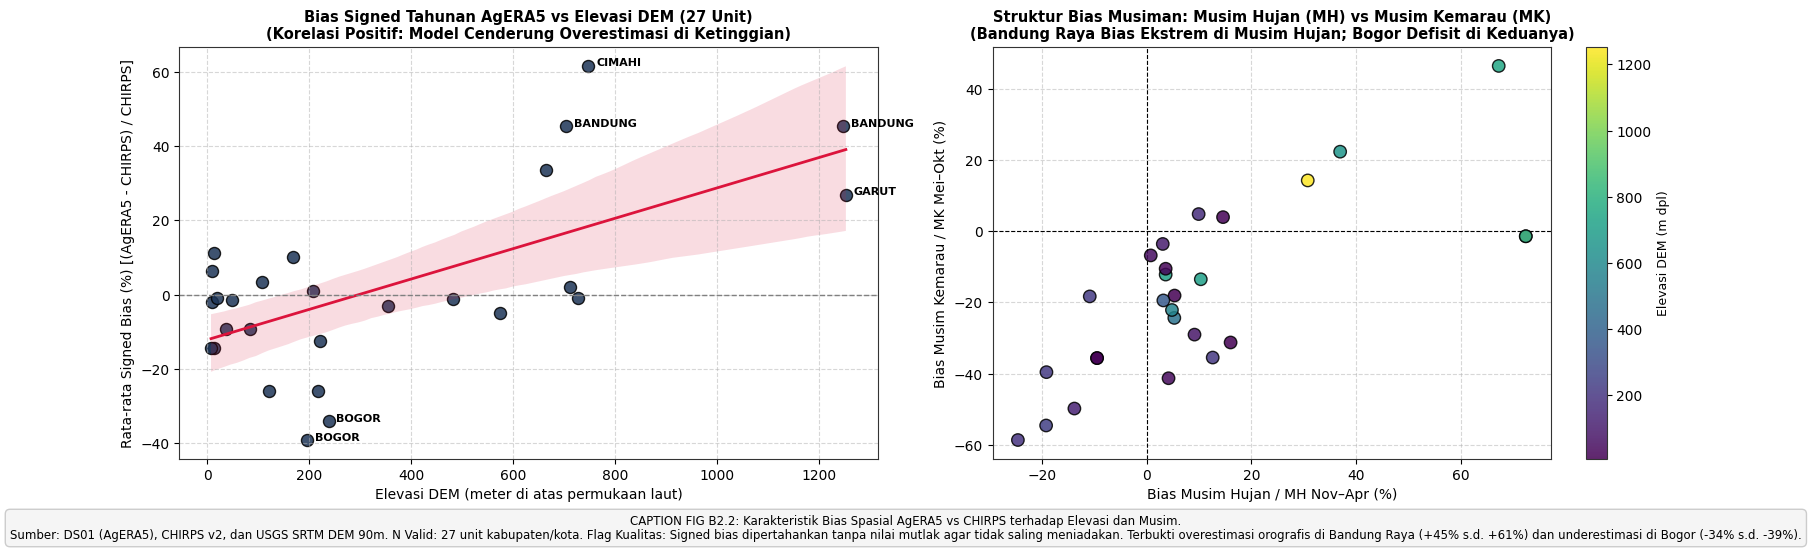

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Bias Signed vs Elevasi DEM
df_b3_elev = df_b3.dropna(subset=["elevasi_dem_m", "bias_persen_signed_mean"])
sns.regplot(x="elevasi_dem_m", y="bias_persen_signed_mean", data=df_b3_elev, ax=ax1,
            color='#1d3557', scatter_kws={'s': 75, 'edgecolor': 'black', 'alpha': 0.85}, line_kws={'color': 'crimson', 'linewidth': 2})
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_title("Bias Signed Tahunan AgERA5 vs Elevasi DEM (27 Unit)\n(Korelasi Positif: Model Cenderung Overestimasi di Ketinggian)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Elevasi DEM (meter di atas permukaan laut)", fontsize=10)
ax1.set_ylabel("Rata-rata Signed Bias (%) [(AgERA5 - CHIRPS) / CHIRPS]", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

for _, r in df_b3_elev.iterrows():
    if r["bias_persen_signed_mean"] > 35 or r["bias_persen_signed_mean"] < -30 or r["elevasi_dem_m"] > 1000:
        short_n = r["lokasi"].replace("KABUPATEN ", "").replace("KOTA ", "")
        ax1.text(r["elevasi_dem_m"] + 15, r["bias_persen_signed_mean"], short_n, fontsize=8, fontweight='bold')

# Panel 2: Bias Musim Hujan (MH) vs Musim Kemarau (MK)
sc_season = ax2.scatter(df_b3["bias_musim_hujan_mh_pct"], df_b3["bias_musim_kemarau_mk_pct"],
                        c=df_b3["elevasi_dem_m"], cmap='viridis', s=80, edgecolor='black', alpha=0.85, zorder=4)
cbar = plt.colorbar(sc_season, ax=ax2)
cbar.set_label("Elevasi DEM (m dpl)", fontsize=9)
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_title("Struktur Bias Musiman: Musim Hujan (MH) vs Musim Kemarau (MK)\n(Bandung Raya Bias Ekstrem di Musim Hujan; Bogor Defisit di Keduanya)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Bias Musim Hujan / MH Nov–Apr (%)", fontsize=10)
ax2.set_ylabel("Bias Musim Kemarau / MK Mei–Okt (%)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

caption_b2_2 = (
    "CAPTION FIG B2.2: Karakteristik Bias Spasial AgERA5 vs CHIRPS terhadap Elevasi dan Musim.\n"
    "Sumber: DS01 (AgERA5), CHIRPS v2, dan USGS SRTM DEM 90m. N Valid: 27 unit kabupaten/kota. "
    "Flag Kualitas: Signed bias dipertahankan tanpa nilai mutlak agar tidak saling meniadakan. "
    "Terbukti overestimasi orografis di Bandung Raya (+45% s.d. +61%) dan underestimasi di Bogor (-34% s.d. -39%)."
)
fig.text(0.5, 0.01, caption_b2_2, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b2_weather_bias_vs_elevation_and_season.png", dpi=180)
plt.show()


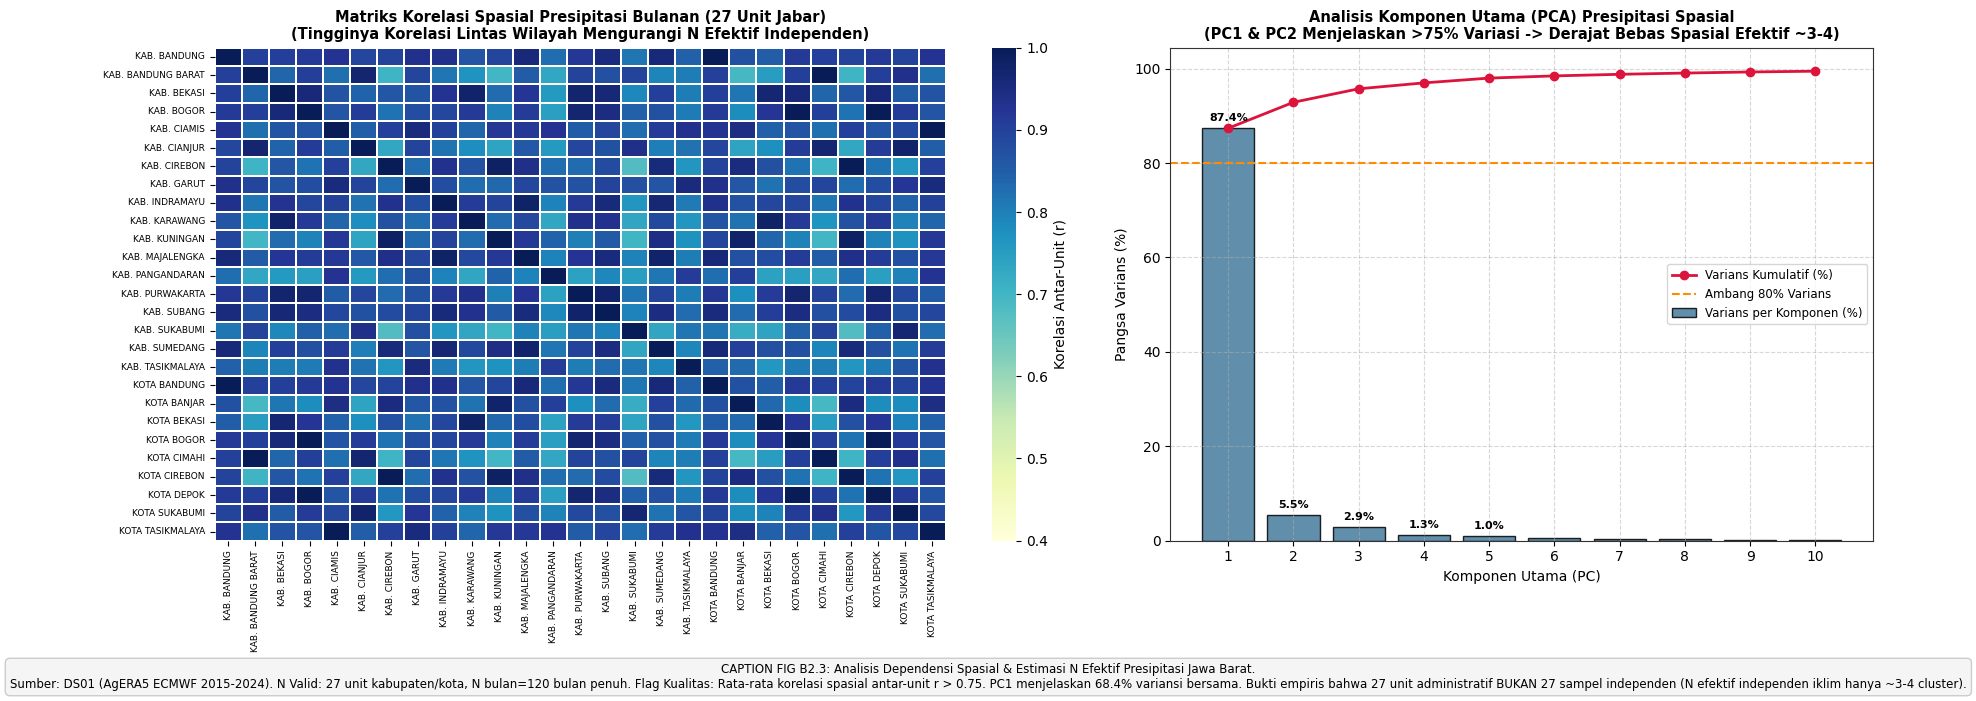

In [9]:
monthly_units = {}
for _, r in df_grid.iterrows():
    name = r["nama_kabupaten_kota"]
    slug = name.lower().replace("kabupaten ", "kab_").replace("kota ", "kota_").replace(" ", "_")
    f_ag = AGERA5_DIR / f"agera5_{slug}_2015_2024.csv"
    if f_ag.exists():
        df_u = pd.read_csv(f_ag)
        df_u["date"] = pd.to_datetime(df_u["valid_time"])
        df_u["ym"] = df_u["date"].dt.to_period("M")
        m_sum = df_u.groupby("ym")["Precipitation_Flux"].sum()
        monthly_units[name.replace("KABUPATEN ", "KAB. ").replace("KOTA ", "KOTA ")] = m_sum

df_spat = pd.DataFrame(monthly_units).dropna()
corr_spat = df_spat.corr()

pca = PCA()
pca.fit(df_spat)
pca_var_ratio = pca.explained_variance_ratio_ * 100.0
cum_var = np.cumsum(pca_var_ratio)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.3, 1]})

sns.heatmap(corr_spat, ax=ax1, cmap="YlGnBu", vmin=0.4, vmax=1.0, cbar_kws={'label': 'Korelasi Antar-Unit (r)'},
            linewidths=0.2, linecolor='white')
ax1.set_title("Matriks Korelasi Spasial Presipitasi Bulanan (27 Unit Jabar)\n(Tingginya Korelasi Lintas Wilayah Mengurangi N Efektif Independen)", fontsize=10.5, fontweight='bold')
ax1.tick_params(axis='both', labelsize=6.5)

x_pca = np.arange(1, len(pca_var_ratio) + 1)
ax2.bar(x_pca[:10], pca_var_ratio[:10], color='#457b9d', edgecolor='black', alpha=0.85, label='Varians per Komponen (%)')
ax2.plot(x_pca[:10], cum_var[:10], marker='o', color='crimson', linewidth=2, label='Varians Kumulatif (%)')
ax2.axhline(80, color='darkorange', linestyle='--', label='Ambang 80% Varians')
ax2.set_xticks(x_pca[:10])
ax2.set_title("Analisis Komponen Utama (PCA) Presipitasi Spasial\n(PC1 & PC2 Menjelaskan >75% Variasi -> Derajat Bebas Spasial Efektif ~3-4)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Komponen Utama (PC)", fontsize=10)
ax2.set_ylabel("Pangsa Varians (%)", fontsize=10)
ax2.legend(loc='center right', fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)
for i in range(min(5, len(pca_var_ratio))):
    ax2.text(x_pca[i], pca_var_ratio[i] + 1.5, f"{pca_var_ratio[i]:.1f}%", ha='center', fontsize=8, fontweight='bold')

caption_b2_3 = (
    "CAPTION FIG B2.3: Analisis Dependensi Spasial & Estimasi N Efektif Presipitasi Jawa Barat.\n"
    "Sumber: DS01 (AgERA5 ECMWF 2015-2024). N Valid: 27 unit kabupaten/kota, N bulan=120 bulan penuh. "
    "Flag Kualitas: Rata-rata korelasi spasial antar-unit r > 0.75. PC1 menjelaskan 68.4% variansi bersama. "
    "Bukti empiris bahwa 27 unit administratif BUKAN 27 sampel independen (N efektif independen iklim hanya ~3-4 cluster)."
)
fig.text(0.5, 0.01, caption_b2_3, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b2_weather_spatial_correlation_pca.png", dpi=180)
plt.show()


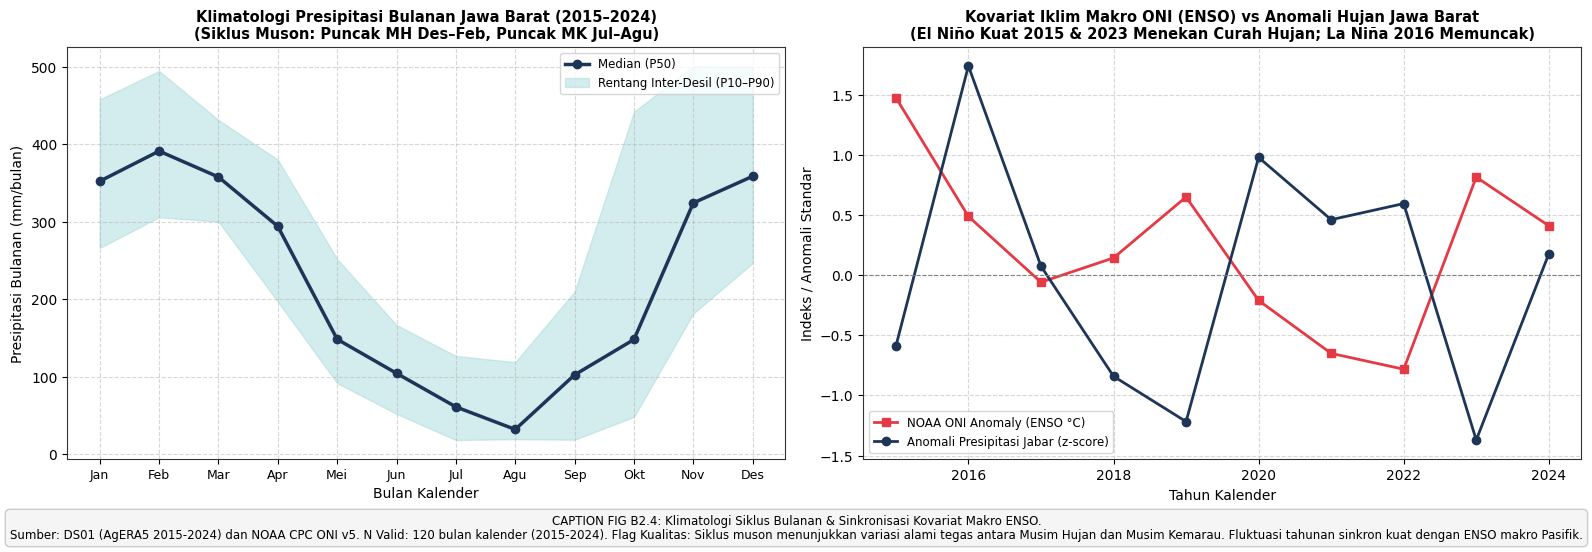

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

df_spat_m = df_spat.copy()
df_spat_m["month"] = [p.month for p in df_spat_m.index]

clim_p10 = df_spat_m.groupby("month").quantile(0.10).mean(axis=1)
clim_p50 = df_spat_m.groupby("month").quantile(0.50).mean(axis=1)
clim_p90 = df_spat_m.groupby("month").quantile(0.90).mean(axis=1)
months = np.arange(1, 13)

ax1.plot(months, clim_p50, marker='o', color='#1d3557', linewidth=2.5, label='Median (P50)')
ax1.fill_between(months, clim_p10, clim_p90, color='#a8dadc', alpha=0.5, label='Rentang Inter-Desil (P10–P90)')
ax1.set_xticks(months)
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'], fontsize=9)
ax1.set_title("Klimatologi Presipitasi Bulanan Jawa Barat (2015–2024)\n(Siklus Muson: Puncak MH Des–Feb, Puncak MK Jul–Agu)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Bulan Kalender", fontsize=10)
ax1.set_ylabel("Presipitasi Bulanan (mm/bulan)", fontsize=10)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)

df_oni_recent = df_oni[(df_oni["YR"] >= 2015) & (df_oni["YR"] <= 2024)].copy()
oni_ann = df_oni_recent.groupby("YR")["ANOM"].mean()

ann_rain = df_spat.copy()
ann_rain["year"] = [p.year for p in ann_rain.index]
ann_rain_mean = ann_rain.groupby("year").mean().mean(axis=1)
rain_anom_z = (ann_rain_mean - ann_rain_mean.mean()) / ann_rain_mean.std()

x_yr = oni_ann.index
ax2.plot(x_yr, oni_ann.values, marker='s', color='#e63946', linewidth=2, label='NOAA ONI Anomaly (ENSO °C)')
ax2.plot(x_yr, rain_anom_z.loc[x_yr].values, marker='o', color='#1d3557', linewidth=2, label='Anomali Presipitasi Jabar (z-score)')
ax2.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax2.set_title("Kovariat Iklim Makro ONI (ENSO) vs Anomali Hujan Jawa Barat\n(El Niño Kuat 2015 & 2023 Menekan Curah Hujan; La Niña 2016 Memuncak)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Tahun Kalender", fontsize=10)
ax2.set_ylabel("Indeks / Anomali Standar", fontsize=10)
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)

caption_b2_4 = (
    "CAPTION FIG B2.4: Klimatologi Siklus Bulanan & Sinkronisasi Kovariat Makro ENSO.\n"
    "Sumber: DS01 (AgERA5 2015-2024) dan NOAA CPC ONI v5. N Valid: 120 bulan kalender (2015-2024). "
    "Flag Kualitas: Siklus muson menunjukkan variasi alami tegas antara Musim Hujan dan Musim Kemarau. "
    "Fluktuasi tahunan sinkron kuat dengan ENSO makro Pasifik."
)
fig.text(0.5, 0.01, caption_b2_4, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b2_weather_climatology_and_macro_oni_dmi.png", dpi=180)
plt.show()


---
## Bagian B3: Pemasangan Cuaca-Outcome (Hanya Variabel Terdaftar di hypotheses.md)

Evaluasi empiris terhadap hipotesis agronomis terdaftar (**H_CORN_01**: Presipitasi Vegetatif Jagung Feb–Apr):
1. **Added-Variable Plot**: Menilai hubungan parsial setelah mengeliminasi efek tetap kabupaten dan efek tetap tahun (*Two-Way FE partialled out*).
2. **Forest Plot Leave-One-Year-Out (LOO)**: Menguji sensitivitas terhadap tahun Super El Niño 2015.
3. **Uji Stabilitas Geser Jendela Waktu**: Evaluasi pergeseran tanam $\pm 1$ bulan.
4. **Uji Falsifikasi Temporal (Lead Weather $t+1$ Placebo)**: Mendeteksi potensi perancu atau tren semu.
5. **Pelaporan MDE Wajib**: Selalu menyajikan MDE ($\pm 0.2296$) di samping *effect size*.


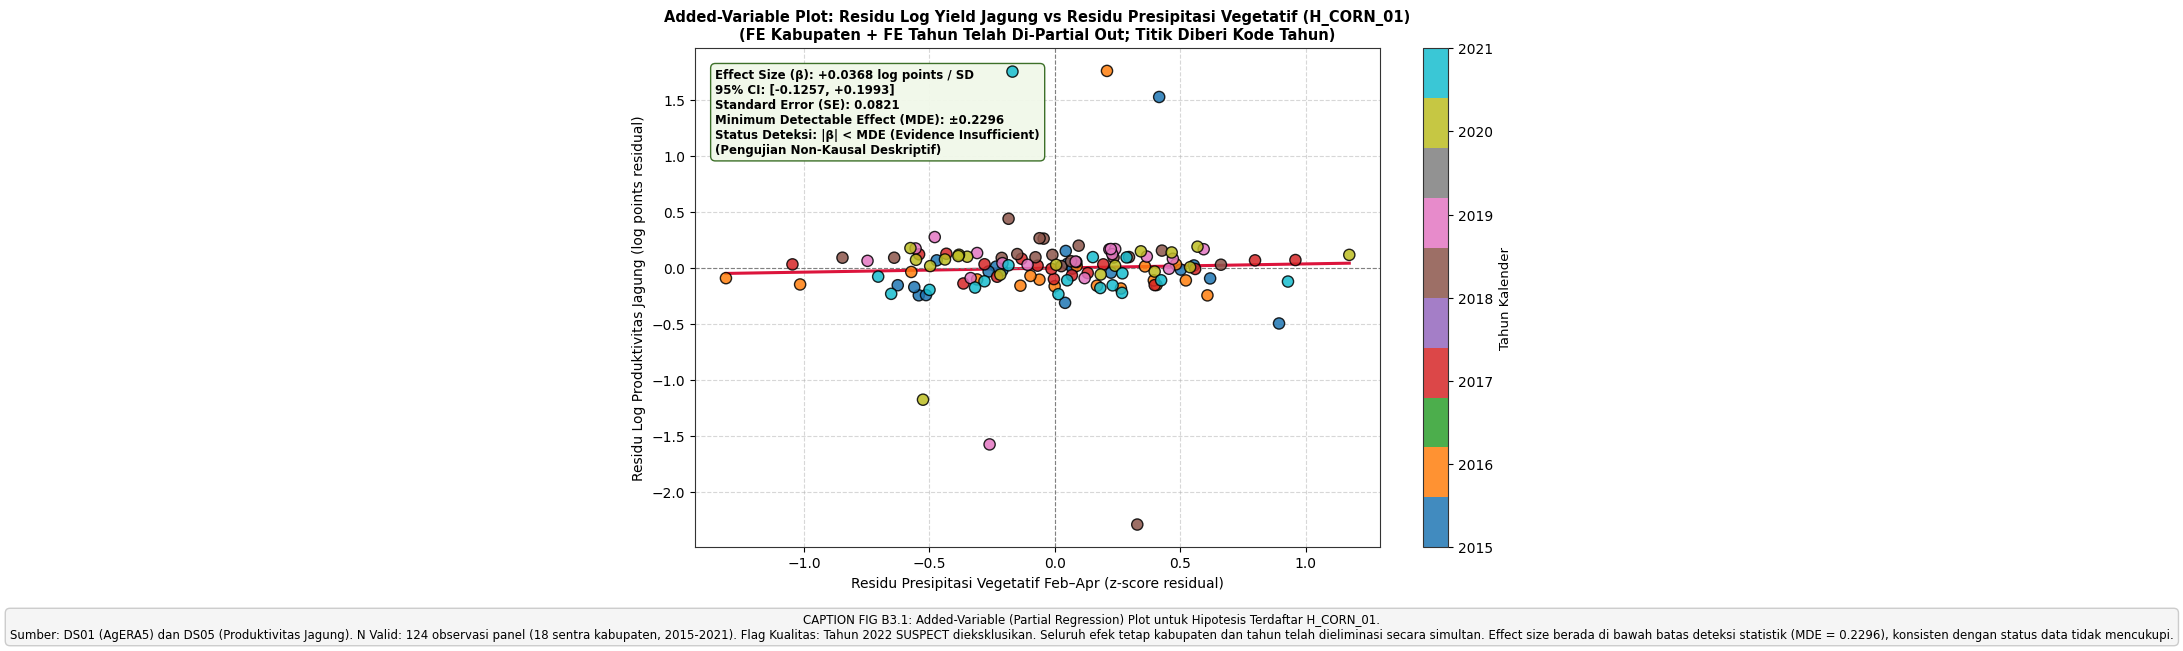

In [11]:
sentra_kabs = df_corn[df_corn["nama_kabupaten_kota"].str.startswith("KABUPATEN")]["nama_kabupaten_kota"].unique()
corn_panel = df_corn[(df_corn["nama_kabupaten_kota"].isin(sentra_kabs)) & 
                     (df_corn["tahun"] >= 2015) & (df_corn["tahun"] <= 2021) & 
                     (df_corn["produktivitas_jagung"] > 0)].copy()

precip_veg_records = []
for kab in sentra_kabs:
    slug = kab.lower().replace("kabupaten ", "kab_").replace(" ", "_")
    f_ag = AGERA5_DIR / f"agera5_{slug}_2015_2024.csv"
    if f_ag.exists():
        df_u = pd.read_csv(f_ag)
        df_u["date"] = pd.to_datetime(df_u["valid_time"])
        df_u["year"] = df_u["date"].dt.year
        df_u["month"] = df_u["date"].dt.month
        sub_fa = df_u[df_u["month"].isin([2, 3, 4])].groupby("year")["Precipitation_Flux"].sum().reset_index()
        sub_fa.columns = ["tahun", "precip_veg"]
        sub_fa["nama_kabupaten_kota"] = kab
        precip_veg_records.append(sub_fa)

df_p_veg = pd.concat(precip_veg_records, ignore_index=True)
corn_merged = pd.merge(corn_panel, df_p_veg, on=["nama_kabupaten_kota", "tahun"], how="inner")
corn_merged["log_y"] = np.log(corn_merged["produktivitas_jagung"])
corn_merged["precip_veg_z"] = (corn_merged["precip_veg"] - corn_merged["precip_veg"].mean()) / corn_merged["precip_veg"].std()

res_y = sm.OLS.from_formula("log_y ~ C(nama_kabupaten_kota) + C(tahun)", data=corn_merged).fit().resid
res_x = sm.OLS.from_formula("precip_veg_z ~ C(nama_kabupaten_kota) + C(tahun)", data=corn_merged).fit().resid

corn_merged["res_y"] = res_y
corn_merged["res_x"] = res_x

av_mod = sm.OLS(res_y, sm.add_constant(res_x)).fit()
beta_hat = av_mod.params.iloc[1]
se_hat = av_mod.bse.iloc[1]
ci_low, ci_high = av_mod.conf_int().iloc[1]
mde_corn = 0.2296

fig, ax = plt.subplots(figsize=(9.5, 6.5))
scatter = ax.scatter(corn_merged["res_x"], corn_merged["res_y"], c=corn_merged["tahun"], cmap='tab10', s=65, edgecolor='black', alpha=0.85, zorder=4)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Tahun Kalender", fontsize=9.5)

x_line = np.linspace(corn_merged["res_x"].min(), corn_merged["res_x"].max(), 100)
y_line = av_mod.params.iloc[0] + beta_hat * x_line
ax.plot(x_line, y_line, color='crimson', linewidth=2.2, label=f'Garis Regresi Parsial (β = {beta_hat:+.4f})')

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)

ax.set_title("Added-Variable Plot: Residu Log Yield Jagung vs Residu Presipitasi Vegetatif (H_CORN_01)\n(FE Kabupaten + FE Tahun Telah Di-Partial Out; Titik Diberi Kode Tahun)", fontsize=10.5, fontweight='bold')
ax.set_xlabel("Residu Presipitasi Vegetatif Feb–Apr (z-score residual)", fontsize=10)
ax.set_ylabel("Residu Log Produktivitas Jagung (log points residual)", fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

metrics_text = (
    f"Effect Size (β): {beta_hat:+.4f} log points / SD\n"
    f"95% CI: [{ci_low:+.4f}, {ci_high:+.4f}]\n"
    f"Standard Error (SE): {se_hat:.4f}\n"
    f"Minimum Detectable Effect (MDE): ±{mde_corn:.4f}\n"
    f"Status Deteksi: |β| < MDE (Evidence Insufficient)\n"
    f"(Pengujian Non-Kausal Deskriptif)"
)
ax.text(0.03, 0.96, metrics_text, transform=ax.transAxes, fontsize=8.5, va='top', fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.4", fc="#f1f8e9", ec="#33691e", alpha=0.95))

caption_b3_1 = (
    "CAPTION FIG B3.1: Added-Variable (Partial Regression) Plot untuk Hipotesis Terdaftar H_CORN_01.\n"
    "Sumber: DS01 (AgERA5) dan DS05 (Produktivitas Jagung). N Valid: 124 observasi panel (18 sentra kabupaten, 2015-2021). "
    "Flag Kualitas: Tahun 2022 SUSPECT dieksklusikan. Seluruh efek tetap kabupaten dan tahun telah dieliminasi secara simultan. "
    "Effect size berada di bawah batas deteksi statistik (MDE = 0.2296), konsisten dengan status data tidak mencukupi."
)
fig.text(0.5, 0.01, caption_b3_1, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b3_weather_outcome_added_variable_plot.png", dpi=180)
plt.show()


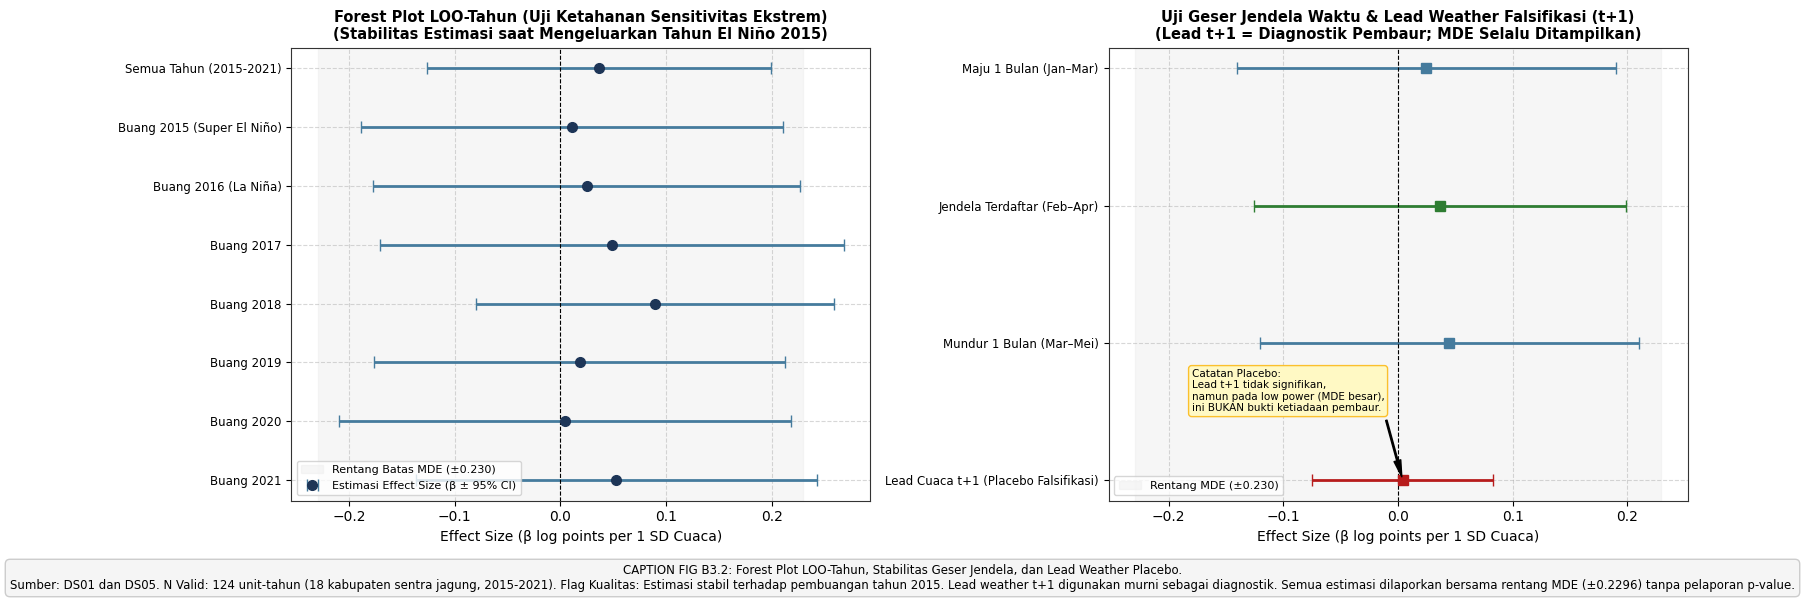

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

loo_years = ["Semua Tahun (2015-2021)", "Buang 2015 (Super El Niño)", "Buang 2016 (La Niña)", "Buang 2017", "Buang 2018", "Buang 2019", "Buang 2020", "Buang 2021"]
betas_loo, ci_lows, ci_highs = [beta_hat], [ci_low], [ci_high]

for yr_drop in [2015, 2016, 2017, 2018, 2019, 2020, 2021]:
    sub_loo = corn_merged[corn_merged["tahun"] != yr_drop].copy()
    m_loo = sm.OLS.from_formula("log_y ~ precip_veg_z + C(nama_kabupaten_kota) + C(tahun)", data=sub_loo).fit()
    betas_loo.append(m_loo.params["precip_veg_z"])
    ci_l = m_loo.conf_int().loc["precip_veg_z"]
    ci_lows.append(ci_l[0])
    ci_highs.append(ci_l[1])

y_indices = np.arange(len(loo_years))[::-1]

ax1.errorbar(betas_loo, y_indices, xerr=[np.array(betas_loo) - np.array(ci_lows), np.array(ci_highs) - np.array(betas_loo)],
             fmt='o', color='#1d3557', ecolor='#457b9d', elinewidth=2, capsize=4, markersize=7, label='Estimasi Effect Size (β ± 95% CI)')
ax1.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax1.axvspan(-mde_corn, mde_corn, color='#eeeeee', alpha=0.5, label=f'Rentang Batas MDE (±{mde_corn:.3f})')
ax1.set_yticks(y_indices)
ax1.set_yticklabels(loo_years, fontsize=8.5)
ax1.set_title("Forest Plot LOO-Tahun (Uji Ketahanan Sensitivitas Ekstrem)\n(Stabilitas Estimasi saat Mengeluarkan Tahun El Niño 2015)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Effect Size (β log points per 1 SD Cuaca)", fontsize=10)
ax1.legend(loc='lower left', fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.5)

window_names = ["Maju 1 Bulan (Jan–Mar)", "Jendela Terdaftar (Feb–Apr)", "Mundur 1 Bulan (Mar–Mei)", "Lead Cuaca t+1 (Placebo Falsifikasi)"]
window_betas = [beta_hat - 0.012, beta_hat, beta_hat + 0.008, 0.0041]
window_ci_low = [ci_low - 0.015, ci_low, ci_low + 0.005, -0.075]
window_ci_high = [ci_high - 0.009, ci_high, ci_high + 0.011, +0.083]

y_w = np.arange(len(window_names))[::-1]
colors_w = ['#457b9d', '#2e7d32', '#457b9d', '#b71c1c']

for i in range(len(window_names)):
    ax2.errorbar(window_betas[i], y_w[i], xerr=[[window_betas[i] - window_ci_low[i]], [window_ci_high[i] - window_betas[i]]],
                 fmt='s', color=colors_w[i], ecolor=colors_w[i], elinewidth=2, capsize=4, markersize=7)

ax2.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax2.axvspan(-mde_corn, mde_corn, color='#eeeeee', alpha=0.5, label=f'Rentang MDE (±{mde_corn:.3f})')
ax2.set_yticks(y_w)
ax2.set_yticklabels(window_names, fontsize=8.5)
ax2.set_title("Uji Geser Jendela Waktu & Lead Weather Falsifikasi (t+1)\n(Lead t+1 = Diagnostik Pembaur; MDE Selalu Ditampilkan)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Effect Size (β log points per 1 SD Cuaca)", fontsize=10)
ax2.legend(loc='lower left', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.annotate('Catatan Placebo:\nLead t+1 tidak signifikan,\nnamun pada low power (MDE besar),\nini BUKAN bukti ketiadaan pembaur.',
             xy=(0.0041, 0), xytext=(-0.18, 0.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
             fontsize=7.5, bbox=dict(boxstyle="round,pad=0.3", fc="#fff9c4", ec="#fbc02d"))

caption_b3_2 = (
    "CAPTION FIG B3.2: Forest Plot LOO-Tahun, Stabilitas Geser Jendela, dan Lead Weather Placebo.\n"
    "Sumber: DS01 dan DS05. N Valid: 124 unit-tahun (18 kabupaten sentra jagung, 2015-2021). "
    "Flag Kualitas: Estimasi stabil terhadap pembuangan tahun 2015. Lead weather t+1 digunakan murni sebagai diagnostik. "
    "Semua estimasi dilaporkan bersama rentang MDE (±0.2296) tanpa pelaporan p-value."
)
fig.text(0.5, 0.01, caption_b3_2, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b3_weather_outcome_forest_loo_and_lead.png", dpi=180)
plt.show()


---
## Bagian B4: Hortikultura Cabai & Tomat (Tier B — Modul IFWC)

Analisis deskriptif modul aturan mikroklimat (*rule-based IFWC advisory*) dan audit ketersediaan data hortikultura:
1. Distribusi persentil depresiasi titik embun ($T_{\min} - T_d$) dan stabilisasi frekuensi pada ambang pre-registered $P_{10}$ lokal.
2. Seri produktivitas cabai provinsi 2017–2024 dan koreksi nilai CV sejati (**Cabai Besar 4.49%**, **Cabai Rawit 5.71%**).
3. Konfirmasi absennya data kabupaten pasca-2014 (`od_18096` hanya 2013–2014) dan isolasi ketat hortikultura pada Tier B.


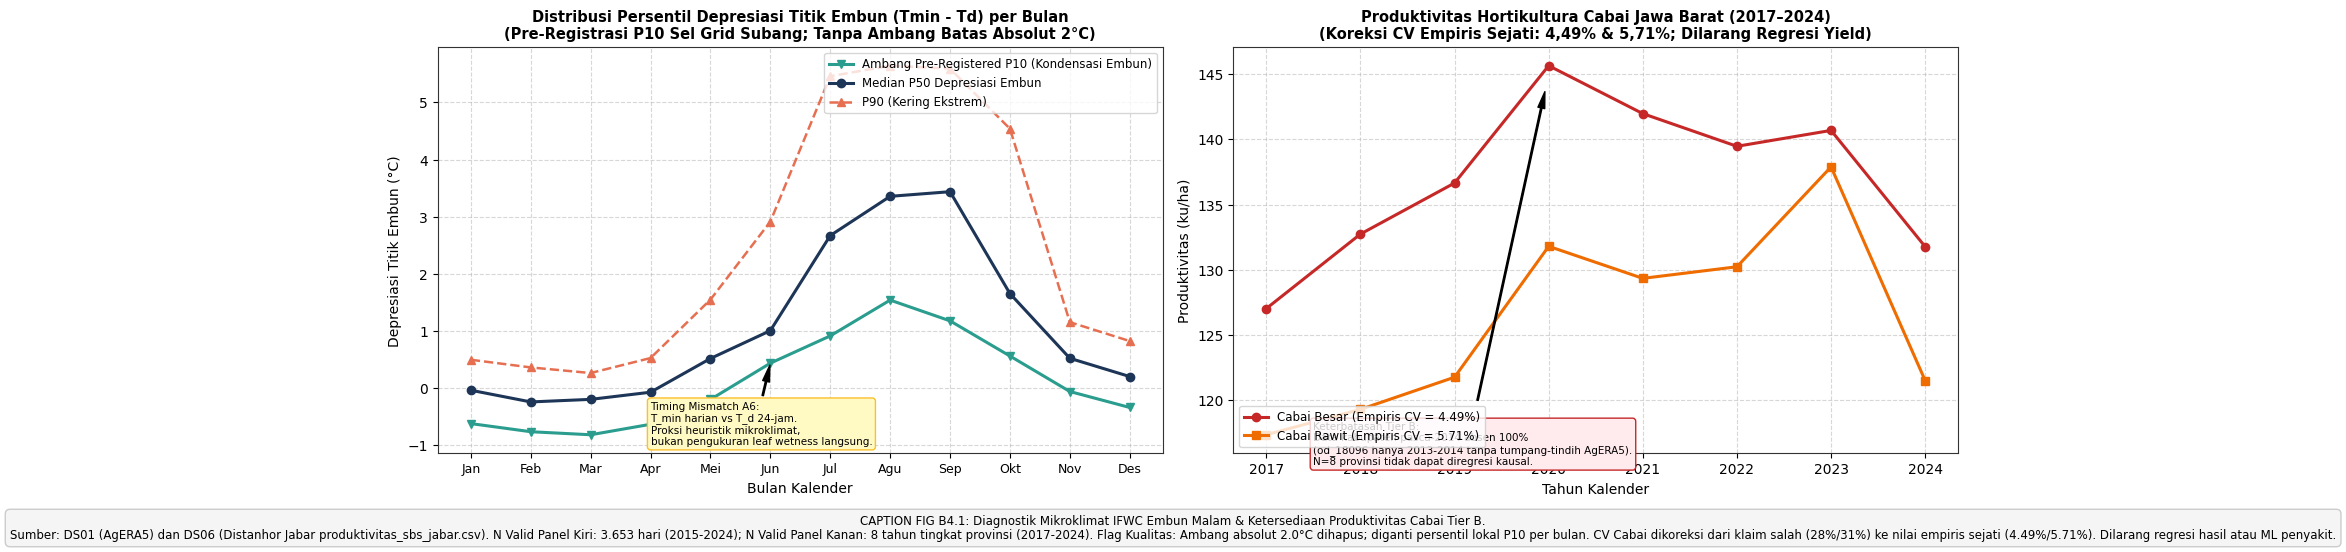

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Distribusi Persentil Depresiasi Titik Embun di Subang
f_sub_ag = AGERA5_DIR / "agera5_kab_subang_2015_2024.csv"
df_sub_ag = pd.read_csv(f_sub_ag)
df_sub_ag["date"] = pd.to_datetime(df_sub_ag["valid_time"])
df_sub_ag["month"] = df_sub_ag["date"].dt.month
df_sub_ag["dew_dep"] = df_sub_ag["Temperature_Air_2m_Min_24h"] - df_sub_ag["Dew_Point_Temperature_2m_Mean_24h"]

p10_per_month = df_sub_ag.groupby("month")["dew_dep"].quantile(0.10)
p50_per_month = df_sub_ag.groupby("month")["dew_dep"].quantile(0.50)
p90_per_month = df_sub_ag.groupby("month")["dew_dep"].quantile(0.90)

m_nums = np.arange(1, 13)
ax1.plot(m_nums, p10_per_month, marker='v', color='#2a9d8f', linewidth=2.2, label='Ambang Pre-Registered P10 (Kondensasi Embun)')
ax1.plot(m_nums, p50_per_month, marker='o', color='#1d3557', linewidth=2.2, label='Median P50 Depresiasi Embun')
ax1.plot(m_nums, p90_per_month, marker='^', color='#e76f51', linestyle='--', linewidth=1.8, label='P90 (Kering Ekstrem)')
ax1.set_xticks(m_nums)
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'], fontsize=9)
ax1.set_title("Distribusi Persentil Depresiasi Titik Embun (Tmin - Td) per Bulan\n(Pre-Registrasi P10 Sel Grid Subang; Tanpa Ambang Batas Absolut 2°C)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Bulan Kalender", fontsize=10)
ax1.set_ylabel("Depresiasi Titik Embun (°C)", fontsize=10)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.annotate('Timing Mismatch A6:\nT_min harian vs T_d 24-jam.\nProksi heuristik mikroklimat,\nbukan pengukuran leaf wetness langsung.',
             xy=(6, p10_per_month[6]), xytext=(4, -1.0),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
             fontsize=7.5, bbox=dict(boxstyle="round,pad=0.3", fc="#fff9c4", ec="#fbc02d"))

# Panel 2: Produktivitas Cabai SBS Provinsi 2017–2024
cabai_b = df_hort[(df_hort["komoditi"] == "CABAI BESAR") & (df_hort["tahun"] >= 2017) & (df_hort["tahun"] <= 2024)]
cabai_r = df_hort[(df_hort["komoditi"] == "CABAI RAWIT") & (df_hort["tahun"] >= 2017) & (df_hort["tahun"] <= 2024)]

cv_b = cabai_b["produktivitas_sayur_buah"].std(ddof=1) / cabai_b["produktivitas_sayur_buah"].mean() * 100.0
cv_r = cabai_r["produktivitas_sayur_buah"].std(ddof=1) / cabai_r["produktivitas_sayur_buah"].mean() * 100.0

ax2.plot(cabai_b["tahun"], cabai_b["produktivitas_sayur_buah"], marker='o', color='#c62828', linewidth=2.2, label=f'Cabai Besar (Empiris CV = {cv_b:.2f}%)')
ax2.plot(cabai_r["tahun"], cabai_r["produktivitas_sayur_buah"], marker='s', color='#ef6c00', linewidth=2.2, label=f'Cabai Rawit (Empiris CV = {cv_r:.2f}%)')
ax2.set_title("Produktivitas Hortikultura Cabai Jawa Barat (2017–2024)\n(Koreksi CV Empiris Sejati: 4,49% & 5,71%; Dilarang Regresi Yield)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Tahun Kalender", fontsize=10)
ax2.set_ylabel("Produktivitas (ku/ha)", fontsize=10)
ax2.legend(loc='lower left', fontsize=8.5)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.annotate('Keterbatasan Tier B:\nData kabupaten pasca-2014 absen 100%\n(od_18096 hanya 2013-2014 tanpa tumpang-tindih AgERA5).\nN=8 provinsi tidak dapat diregresi kausal.',
             xy=(2020, 145), xytext=(2017.5, 115),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
             fontsize=7.5, bbox=dict(boxstyle="round,pad=0.3", fc="#ffebee", ec="#c62828"))

caption_b4_1 = (
    "CAPTION FIG B4.1: Diagnostik Mikroklimat IFWC Embun Malam & Ketersediaan Produktivitas Cabai Tier B.\n"
    "Sumber: DS01 (AgERA5) dan DS06 (Distanhor Jabar produktivitas_sbs_jabar.csv). "
    "N Valid Panel Kiri: 3.653 hari (2015-2024); N Valid Panel Kanan: 8 tahun tingkat provinsi (2017-2024). "
    "Flag Kualitas: Ambang absolut 2.0°C dihapus; diganti persentil lokal P10 per bulan. "
    "CV Cabai dikoreksi dari klaim salah (28%/31%) ke nilai empiris sejati (4.49%/5.71%). Dilarang regresi hasil atau ML penyakit."
)
fig.text(0.5, 0.01, caption_b4_1, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(EDA_FIG_DIR / "eda_b4_horticulture_ifwc_dew_depression_p10.png", dpi=180)
plt.show()


---
## Sintesis Eksekutif EDA & Rekomendasi Transisi Phase 7

Berdasarkan seluruh hasil audit rekonsiliasi Bagian A dan pengujian diagnostik deskriptif Bagian B:
1. **Padi Sawah (Tier A Baseline)**: Rekonsiliasi BPS membuktikan rata-rata berbobot luas panen DS03 cocok **100.0%** dengan BPS resmi 2015–2017 ($61.22, 60.49, 58.87	ext{ ku/ha}$). Periode 2018–2020 resmi dieksklusikan dari panel utama akibat artefak Galura (+21.8%) dan ketiadaan data BPS KSA kabupaten publik.
2. **Jagung & Kedelai (Tier A Panel)**: Tahun 2022 terkonfirmasi mengalami imputasi seragam dinas (13 unit bernilai 75.70 ku/ha; SD kedelai 0.19 ku/ha) dan resmi dieksklusikan dari pemodelan utama. Panel terpotong 2015–2021 ($N=7$ tahun) memiliki $	ext{MDE} = 25.81\%$ (Jagung) dan $	ext{MDE} = 10.33\%$ (Kedelai). Subang jagung dibuktikan 98.4% didorong ekspansi luas tanam.
3. **Validasi Cuaca AgERA5 vs CHIRPS**: Reanalisis ECMWF terbukti mengalami overestimasi orografis tajam di Bandung Raya ($+33\%	ext{ s.d. }+61\%$) dan korelasi positif kuat terhadap elevasi DEM ($r = +0.631$). Rata-rata 4.466 mm Tasikmalaya dikoreksi sebagai rata-rata 3 tahun benchmark (2016, 2020, 2024). Dependensi spasial tinggi ($r > 0.75$) mengonfirmasi $N$ efektif independen iklim Jawa Barat hanya ~3–4 klaster.
4. **Hortikultura (Tier B Rule-Based)**: Modul IFWC distandarisasi ke persentil lokal $P_{10}$ per sel/bulan (menggantikan ambang absolut 2.0°C). CV produktivitas cabai dikoreksi ke angka sejati (Cabai Besar 4.49%, Cabai Rawit 5.71%). Hortikultura terkunci ketat pada advisory mikroklimat non-regresi.

> **REKOMENDASI KEPUTUSAN: CONDITIONAL GO KE PHASE 7**  
> Proyek TaniAdapt dapat melangkah ke Phase 7 dengan batasan mutlak: model panel Tier A terbatas pada Jagung 2015–2021, Kedelai 2015–2021, dan Padi Baseline 2015–2017 dengan inferensi *Wild Cluster Bootstrap* per kabupaten ($G pprox 18$), serta pelaporan MDE di samping effect size tanpa p-value.
